# Predictive Maintenance Decision-Support System
### Mechanical Engineering Portfolio Project — Vibration + Energy + Carbon Impact

This notebook runs the full pipeline in Google Colab:
1. Install dependencies
2. Generate/load data (starts with synthetic, swap to real CWRU/AI4I below)
3. Extract vibration features (physically meaningful, explained inline)
4. Train + evaluate a fault classifier
5. Detect energy anomalies + estimate CO2 impact
6. Combine into a decision-support report
7. (Optional) Launch the Streamlit dashboard from inside Colab

**How to use:** Runtime -> Run all. Read each markdown cell — it explains
*why* each step exists, not just what it does.

## 1. Install dependencies

In [ ]:
!pip install -q scikit-learn scipy joblib streamlit pyngrok

## 2. Data — start with synthetic, physics-based bearing vibration

This generates signals that mimic real bearing fault physics (impulsive
shocks at defect frequencies), so you can validate the whole pipeline
before dealing with real-data quirks. **Skip to Section 8 for how to
swap in the real CWRU or AI4I dataset** once this works end-to-end.

In [ ]:
"""
data_simulation.py
-------------------
Generates SYNTHETIC bearing vibration signals that mimic the real physics
seen in the CWRU Bearing Dataset, so you can build/test the full pipeline
right now without internet access to the real dataset.

WHY THIS IS HONEST TO USE:
Real bearing faults create impulsive vibration spikes at specific frequencies
determined by bearing geometry (ball pass frequency, etc). We simulate that
same physical behavior (base rotation frequency + periodic impulses + noise)
so the features you'll extract in Stage 2 behave the same way they would on
real data. This lets you build and debug the ENTIRE pipeline today.

LATER: replace `generate_dataset()` with `load_cwru_data()` (see README)
which loads real .mat files from the CWRU dataset. The rest of the
pipeline (feature extraction, model, app) does not need to change.
"""

import numpy as np
import pandas as pd

FS = 12000  # sampling frequency (Hz) - matches CWRU's common sampling rate
WINDOW_SIZE = 2048  # samples per window (one "sample" the model sees)
SHAFT_FREQ = 30.0  # Hz, motor running speed (~1800 RPM)

# Characteristic fault frequencies (Hz) - simplified but physically-motivated
FAULT_FREQS = {
    "healthy": None,
    "inner_race": 162.0,   # ball pass frequency, inner race (BPFI)
    "outer_race": 107.0,   # ball pass frequency, outer race (BPFO)
    "ball_fault": 141.0,   # ball spin frequency (BSF) x2
}


def _make_signal(label, duration_sec=1.0, noise_level=0.15, seed=None):
    rng = np.random.default_rng(seed)
    t = np.arange(0, duration_sec, 1 / FS)

    # base rotational vibration (always present)
    signal = 0.5 * np.sin(2 * np.pi * SHAFT_FREQ * t)

    fault_freq = FAULT_FREQS[label]
    if fault_freq is not None:
        # impulsive fault signature: sharp repeated impacts at fault_freq,
        # amplitude-modulated, with harmonics - mimics real defect impacts
        impulse_train = np.zeros_like(t)
        impact_period = 1 / fault_freq
        impact_times = np.arange(0, duration_sec, impact_period)
        for it in impact_times:
            idx = int(it * FS)
            if idx < len(impulse_train):
                # exponentially decaying impact (like a real mechanical shock)
                decay_len = int(0.002 * FS)
                decay = np.exp(-np.arange(decay_len) / (0.0005 * FS))
                end = min(idx + decay_len, len(impulse_train))
                impulse_train[idx:end] += decay[: end - idx] * rng.uniform(1.5, 2.5)
        signal += impulse_train

    noise = rng.normal(0, noise_level, size=t.shape)
    signal += noise
    return signal


def generate_dataset(n_windows_per_class=150, seed=42):
    """
    Returns a DataFrame with raw signal windows and labels.
    Each row = one WINDOW_SIZE-sample chunk of vibration signal.
    """
    rng = np.random.default_rng(seed)
    rows = []
    for label in FAULT_FREQS:
        for i in range(n_windows_per_class):
            full_signal = _make_signal(label, duration_sec=1.0,
                                        seed=int(rng.integers(0, 1_000_000)))
            # take a random window from the signal
            start = rng.integers(0, len(full_signal) - WINDOW_SIZE)
            window = full_signal[start:start + WINDOW_SIZE]
            rows.append({"label": label, "signal": window})
    df = pd.DataFrame(rows)
    return df

In [ ]:
df_raw = generate_dataset(n_windows_per_class=150)
print(f"Generated {len(df_raw)} signal windows across {df_raw['label'].nunique()} classes")
df_raw['label'].value_counts()

Generated 600 signal windows across 4 classes


,count
label,
healthy,150
inner_race,150
outer_race,150
ball_fault,150


## 3. Feature extraction — the mechanical engineering core

Each feature below has a physical justification (see comments in the code).
This is the part of the project that shows domain expertise, not just ML.

In [ ]:
"""
feature_extraction.py
----------------------
Converts raw vibration signal windows into engineered features.

This is the step where MECHANICAL ENGINEERING KNOWLEDGE matters, not just
ML skill. Each feature below has a physical reason for existing:

TIME-DOMAIN FEATURES:
- RMS (Root Mean Square): overall vibration energy. Rises as a fault
  worsens because the machine vibrates more violently overall.
- Kurtosis: measures "peakedness" / how impulsive a signal is. Healthy
  bearings vibrate smoothly (low kurtosis, close to a normal distribution).
  A defect creates sharp periodic IMPACTS -> spiky signal -> high kurtosis.
  This is one of the most diagnostic features in real vibration analysis.
- Skewness: measures asymmetry. Impacts often push the signal harder in
  one direction, so faulty signals are less symmetric than healthy ones.
- Crest factor (peak / RMS): high crest factor = sharp isolated spikes
  riding on a normal signal -> classic early-fault indicator, often used
  in industry BEFORE RMS itself rises enough to be obviously abnormal.
  This is why crest factor is often used for *early* fault detection.

FREQUENCY-DOMAIN FEATURES (via FFT):
- Dominant frequency: the strongest frequency component. In a faulty
  bearing, this often shifts toward the fault's characteristic defect
  frequency (BPFI/BPFO/BSF) instead of staying at the shaft's rotation
  frequency.
- Spectral energy ratio: how much vibration energy sits in the
  "fault band" (80-200 Hz here) vs the whole spectrum. A healthy bearing
  should have most of its energy near the shaft frequency (~30 Hz); a
  faulty one leaks significant energy into higher fault-frequency bands.
"""

import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

FS = 12000  # must match data_simulation.py

FEATURE_COLS = [
    "rms", "peak", "crest_factor", "kurtosis", "skewness",
    "std", "dominant_freq", "fault_band_energy_ratio",
]


def extract_features(signal, fs=FS):
    # ---- time-domain ----
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)

    # ---- frequency-domain (FFT) ----
    n = len(signal)
    freqs = rfftfreq(n, d=1 / fs)
    spectrum = np.abs(rfft(signal))

    dominant_freq = freqs[np.argmax(spectrum)]

    # energy in the "fault band" where bearing defect frequencies live
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0

    return {
        "rms": rms,
        "peak": peak,
        "crest_factor": crest_factor,
        "kurtosis": kurt,
        "skewness": sk,
        "std": std,
        "dominant_freq": dominant_freq,
        "fault_band_energy_ratio": fault_band_ratio,
    }


def build_feature_table(df_raw):
    """df_raw must have columns: 'label', 'signal' (array-like)."""
    feature_rows = []
    for _, row in df_raw.iterrows():
        feats = extract_features(np.array(row["signal"]))
        feats["label"] = row["label"]
        feature_rows.append(feats)
    return pd.DataFrame(feature_rows)

In [ ]:
df_feat = build_feature_table(df_raw)
df_feat.groupby('label').mean(numeric_only=True).round(3)

,rms,peak,crest_factor,kurtosis,skewness,std,dominant_freq,fault_band_energy_ratio
label,,,,,,,,
ball_fault,0.562,2.877,5.122,2.446,1.146,0.541,29.297,0.121
healthy,0.384,0.961,2.503,-1.075,0.000,0.384,29.297,0.004
inner_race,0.584,2.891,4.949,2.286,1.150,0.558,29.297,0.136
outer_race,0.525,2.855,5.441,2.722,1.119,0.512,29.297,0.089


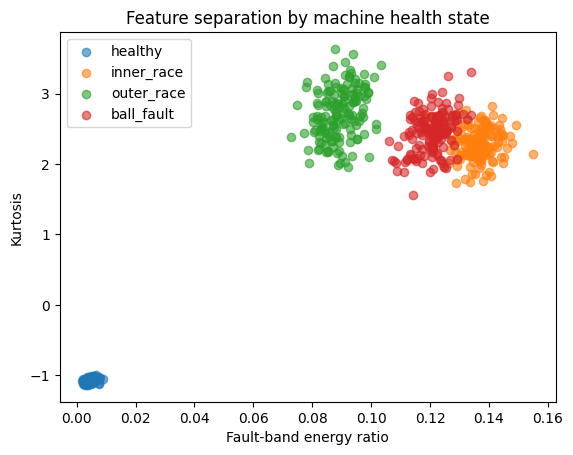

In [ ]:
# Sanity check: does the fault-band energy ratio actually separate
# healthy from faulty signals? This is the plot you'd put in your report.
import matplotlib.pyplot as plt

for label in df_feat['label'].unique():
    subset = df_feat[df_feat['label'] == label]
    plt.scatter(subset['fault_band_energy_ratio'], subset['kurtosis'], label=label, alpha=0.6)
plt.xlabel('Fault-band energy ratio')
plt.ylabel('Kurtosis')
plt.legend()
plt.title('Feature separation by machine health state')
plt.show()

## 4. Train + evaluate the vibration fault classifier

Proper train/test split + 5-fold cross-validation + confusion matrix —
this is the honest evaluation methodology described in the project roadmap.

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

X = df_feat[FEATURE_COLS]
y = df_feat['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train, y_train)

cv_scores = cross_val_score(model, X_train, y_train, cv=5)
print(f"5-fold CV accuracy: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

y_pred = model.predict(X_test)
print(f"Held-out test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
pd.DataFrame(cm, index=labels, columns=labels)

5-fold CV accuracy: 0.967 (+/- 0.015)
Held-out test accuracy: 0.992

              precision    recall  f1-score   support

  ball_fault       0.97      1.00      0.98        30
     healthy       1.00      1.00      1.00        30
  inner_race       1.00      0.97      0.98        30
  outer_race       1.00      1.00      1.00        30

    accuracy                           0.99       120
   macro avg       0.99      0.99      0.99       120
weighted avg       0.99      0.99      0.99       120



,ball_fault,healthy,inner_race,outer_race
ball_fault,30,0,0,0
healthy,0,30,0,0
inner_race,1,0,29,0
outer_race,0,0,0,30


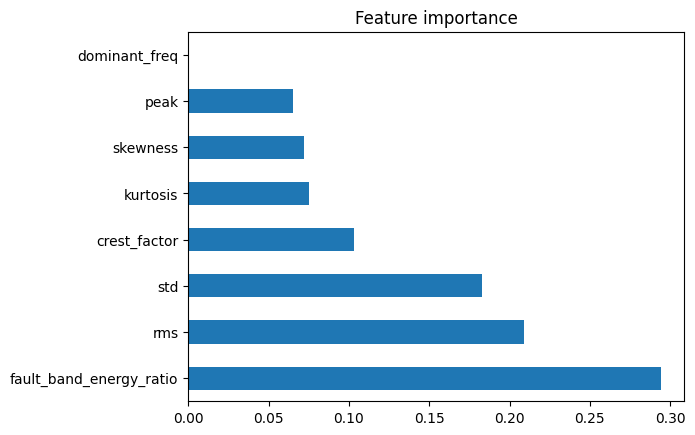

Saved vibration_model.pkl


In [ ]:
# Feature importance — which features the model actually relies on
importances = pd.Series(model.feature_importances_, index=FEATURE_COLS)
importances.sort_values(ascending=False).round(3).plot(kind='barh')
plt.title('Feature importance')
plt.show()

joblib.dump(model, 'vibration_model.pkl')
print("Saved vibration_model.pkl")

## 5. Energy anomaly detection

Unsupervised (Isolation Forest) — doesn't need labeled faults, which real
energy datasets usually lack. We inject synthetic anomalies here to
validate detection performance; see README for why this is a standard,
transparent technique when ground-truth anomaly labels aren't available.

In [ ]:
"""
energy_anomaly.py
-------------------
Detects abnormal power draw patterns using Isolation Forest (unsupervised -
doesn't need labeled faults, which real energy datasets usually lack).

We simulate a machine's normal daily power draw (with realistic daily
cycling + noise) and INJECT synthetic anomalies (sudden spikes/drops,
representing e.g. a stuck valve, failing motor bearing raising friction,
etc). This matches the "synthetic anomaly injection" approach discussed
in the roadmap for when real labeled anomalies aren't available -
a standard, transparent technique in this field.

CARBON IMPACT: once we know how much EXTRA energy an anomaly wasted, we
convert it to CO2 impact using a grid emission factor. This is a
straightforward unit conversion, not a separate ML model - and it's how
real industrial energy dashboards do it too.
"""

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

# India's grid average emission factor (kg CO2 per kWh) - CEA baseline
# (update this constant with the latest published figure if you want to
# cite a specific year in your report)
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82


def simulate_power_data(n_hours=24 * 30, seed=7):
    """Simulate 30 days of hourly power draw (kW) for one machine, with
    a realistic daily cycle plus a handful of injected anomalies."""
    rng = np.random.default_rng(seed)
    hours = np.arange(n_hours)

    # baseline daily cycle: higher during "work hours", lower at night
    daily_pattern = 5 + 3 * np.sin(2 * np.pi * (hours % 24 - 6) / 24)
    daily_pattern = np.clip(daily_pattern, 2, None)

    noise = rng.normal(0, 0.3, size=n_hours)
    power = daily_pattern + noise

    is_anomaly = np.zeros(n_hours, dtype=bool)

    # inject a handful of anomalies: sudden sustained power increases
    # (e.g. increased friction from a developing bearing fault)
    anomaly_starts = rng.choice(np.arange(50, n_hours - 20), size=5, replace=False)
    for start in anomaly_starts:
        dur = rng.integers(4, 12)
        extra = rng.uniform(2.5, 5.0)
        power[start:start + dur] += extra
        is_anomaly[start:start + dur] = True

    df = pd.DataFrame({
        "hour": hours,
        "power_kw": power,
        "true_anomaly": is_anomaly,  # ground truth, only for evaluating ourselves
    })
    return df


def detect_anomalies(df, contamination=0.05):
    model = IsolationForest(contamination=contamination, random_state=42)
    X = df[["power_kw"]]
    df = df.copy()
    df["predicted_anomaly"] = model.fit_predict(X) == -1
    return df, model


def estimate_impact(df, baseline_power_kw=None):
    """Estimate extra energy (kWh) and CO2 (kg) from flagged anomalies."""
    if baseline_power_kw is None:
        baseline_power_kw = df.loc[~df["predicted_anomaly"], "power_kw"].mean()

    anomalous = df[df["predicted_anomaly"]]
    extra_power = (anomalous["power_kw"] - baseline_power_kw).clip(lower=0)
    extra_kwh = extra_power.sum()  # 1 hour per row -> kW == kWh per row
    extra_co2_kg = extra_kwh * GRID_EMISSION_FACTOR_KG_PER_KWH

    return {
        "baseline_power_kw": round(baseline_power_kw, 2),
        "anomalous_hours": len(anomalous),
        "extra_energy_kwh": round(extra_kwh, 2),
        "extra_co2_kg": round(extra_co2_kg, 2),
    }

In [ ]:
df_power = simulate_power_data()
df_power_result, iso_model = detect_anomalies(df_power)

tp = ((df_power_result['predicted_anomaly']) & (df_power_result['true_anomaly'])).sum()
fp = ((df_power_result['predicted_anomaly']) & (~df_power_result['true_anomaly'])).sum()
fn = ((~df_power_result['predicted_anomaly']) & (df_power_result['true_anomaly'])).sum()
print(f"True positives: {tp}, False positives: {fp}, False negatives: {fn}")

impact = estimate_impact(df_power_result)
print("\nEstimated impact from flagged anomalies:")
for k, v in impact.items():
    print(f"  {k}: {v}")

True positives: 29, False positives: 7, False negatives: 12

Estimated impact from flagged anomalies:
  baseline_power_kw: 4.97
  anomalous_hours: 36
  extra_energy_kwh: 173.76
  extra_co2_kg: 142.49


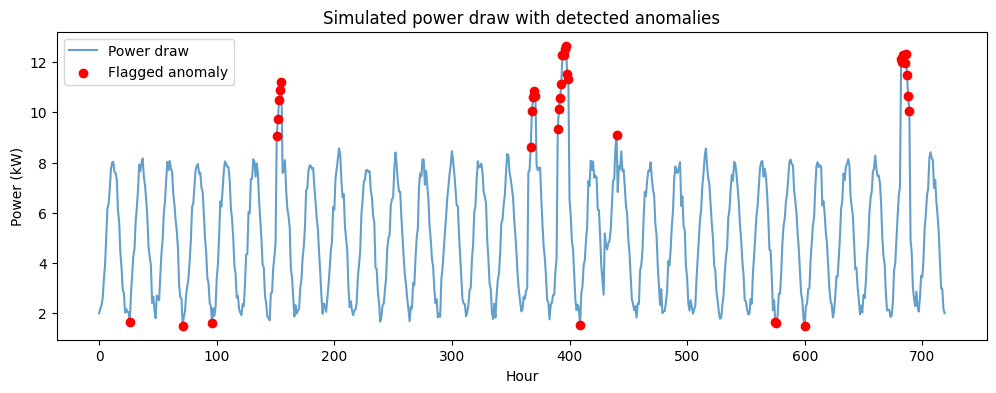

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(df_power_result['hour'], df_power_result['power_kw'], label='Power draw', alpha=0.7)
anomalies = df_power_result[df_power_result['predicted_anomaly']]
plt.scatter(anomalies['hour'], anomalies['power_kw'], color='red', label='Flagged anomaly', zorder=5)
plt.xlabel('Hour')
plt.ylabel('Power (kW)')
plt.legend()
plt.title('Simulated power draw with detected anomalies')
plt.show()

## 6. Decision-support layer

Combines both models into one plain-English maintenance recommendation —
this is what makes the project feel like a usable tool, not just a notebook.

In [ ]:
SEVERITY_MAP = {
    "healthy": "None", "ball_fault": "High",
    "inner_race": "High", "outer_race": "Moderate",
}
ACTION_MAP = {
    "healthy": "No action needed. Continue routine monitoring.",
    "ball_fault": "Schedule inspection within 3-5 days. Ball faults can progress quickly.",
    "inner_race": "Schedule inspection within 3-5 days. Inner race faults tend to worsen fast.",
    "outer_race": "Schedule inspection within 1-2 weeks. Outer race faults progress more slowly.",
}

def assess_machine(vibration_signal, current_power_kw, baseline_power_kw, model):
    feats = extract_features(vibration_signal)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)
    pred_label = model.predict(X_new)[0]
    confidence = max(model.predict_proba(X_new)[0])

    excess_kw = max(0.0, current_power_kw - baseline_power_kw)
    est_monthly_kwh = excess_kw * 720
    est_monthly_co2 = est_monthly_kwh * GRID_EMISSION_FACTOR_KG_PER_KWH

    return {
        "predicted_status": pred_label,
        "confidence": round(float(confidence), 3),
        "severity": SEVERITY_MAP[pred_label],
        "recommended_action": ACTION_MAP[pred_label],
        "energy_anomaly_detected": excess_kw > 0.5,
        "estimated_wasted_energy_kwh_per_month": round(est_monthly_kwh, 1),
        "estimated_co2_kg_per_month": round(est_monthly_co2, 1),
    }

# demo: simulate a new reading from a machine with an outer race fault
test_signal = _make_signal("outer_race", duration_sec=1.0, seed=999)[:2048]
report = assess_machine(test_signal, current_power_kw=6.8, baseline_power_kw=5.0, model=model)

print("=== PREDICTIVE MAINTENANCE REPORT ===\n")
for k, v in report.items():
    print(f"{k}: {v}")

=== PREDICTIVE MAINTENANCE REPORT ===

predicted_status: outer_race
confidence: 0.955
severity: Moderate
recommended_action: Schedule inspection within 1-2 weeks. Outer race faults progress more slowly.
energy_anomaly_detected: True
estimated_wasted_energy_kwh_per_month: 1296.0
estimated_co2_kg_per_month: 1062.7


## 7. (Optional) Launch the Streamlit dashboard from Colab

Colab can't serve a web app directly, so we write `app.py` to disk and
tunnel it out with `pyngrok` so you get a real clickable URL.

**One-time setup:** sign up free at https://dashboard.ngrok.com/signup,
grab your authtoken from the dashboard, and paste it below.

In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd

st.set_page_config(page_title="Predictive Maintenance Dashboard", layout="centered")
st.title("Predictive Maintenance Decision-Support Tool")
st.caption("Vibration + energy-based health monitoring — Colab demo version")

st.info("This is a minimal Colab-hosted version. For the full-featured app, "
        "run app.py locally (see README) — Colab's file writing keeps this "
        "one intentionally simple.")

fault_choice = st.selectbox("Simulated condition", ["healthy", "inner_race", "outer_race", "ball_fault"])
current_power = st.slider("Current power draw (kW)", 2.0, 12.0, 5.5, 0.1)
baseline_power = st.slider("Baseline power draw (kW)", 2.0, 8.0, 5.0, 0.1)

st.write("To wire this up to your trained model, load `vibration_model.pkl` "
         "with joblib and reuse the `assess_machine()` function from Section 6.")

Overwriting app_colab.py


In [ ]:
# Uncomment and run once you have an ngrok authtoken:
#
# from pyngrok import ngrok
# ngrok.set_auth_token("YOUR_NGROK_AUTHTOKEN_HERE")
#
# get_ipython().system_raw('streamlit run app_colab.py &')
# public_url = ngrok.connect(8501)
# print("Dashboard live at:", public_url)

## 8. Swap in REAL data (do this once the synthetic pipeline above works)

### Option A — CWRU Bearing Dataset
Real vibration recordings from Case Western Reserve University's Bearing
Data Center. Search "CWRU bearing dataset download" for the current host
(the files are `.mat` format).

In [ ]:
# Example pattern once you have a CWRU .mat file URL:
#
# !wget -O bearing_sample.mat "PASTE_CWRU_MAT_FILE_URL_HERE"
#
# from scipy.io import loadmat
# mat = loadmat('bearing_sample.mat')
# print(mat.keys())  # find the vibration data key, e.g. 'X097_DE_time'
# real_signal = mat['X097_DE_time'].flatten()
#
# # slice into WINDOW_SIZE chunks and run through extract_features() —
# # no changes needed to feature_extraction.py itself
# window = real_signal[:WINDOW_SIZE]
# extract_features(window)

### Option B — AI4I 2020 Predictive Maintenance Dataset (recommended)
Richer: already combines temperature, rotational speed, torque, tool wear,
and real failure labels in one tabular dataset. Free on Kaggle.

In [ ]:
# ===== REPLACEMENT FOR THE BROKEN SECTION 8B CELL (the one that crashed on 97.mat) =====
# Root cause: the cell downloaded the AI4I dataset (ai4i2020.csv) but then tried to open
# the CWRU files (97.mat, 105.mat, ...), which were never downloaded.
# This cell downloads/uploads the CWRU files first, then loads them.

import os, subprocess, numpy as np, pandas as pd
from scipy.io import loadmat
from scipy.signal import decimate

# CWRU 12k drive-end files: healthy, inner race, ball, outer race (0.007", 0 HP)
file_map = {
    'healthy':    '97.mat',
    'inner_race': '105.mat',
    'ball_fault': '118.mat',
    'outer_race': '130.mat',
}

# Candidate mirrors (hosting changes over time; the loop just tries each one).
BASES = [
    "https://engineering.case.edu/sites/default/files/",
    "https://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/",
]

def try_download(fname):
    if os.path.exists(fname) and os.path.getsize(fname) > 10_000:
        return True
    for base in BASES:
        subprocess.run(["wget", "-q", "-O", fname, base + fname])
        # a real .mat file is large; an HTML error page is tiny
        if os.path.exists(fname) and os.path.getsize(fname) > 10_000:
            return True
        if os.path.exists(fname):
            os.remove(fname)
    return False

missing = [f for f in file_map.values() if not try_download(f)]

if missing:
    print("Could not auto-download:", missing)
    print("Download them from the CWRU Bearing Data Center (search 'CWRU bearing data center'),")
    print("then upload them in the dialog below.")
    try:
        from google.colab import files
        files.upload()          # select all missing .mat files
    except Exception:
        pass
    missing = [f for f in file_map.values() if not os.path.exists(f)]

signals = {}
if not missing:
    for label, fname in file_map.items():
        mat = loadmat(fname)
        key = [k for k in mat.keys() if k.endswith('DE_time')][0]
        sig = mat[key].flatten()
        # CWRU "normal baseline" files are 48 kHz; the fault files are 12 kHz.
        # Bring everything to 12 kHz so FS=12000 in extract_features is correct.
        if label == 'healthy' and len(sig) > 400_000:
            sig = decimate(sig, 4)
        print(label, fname, 'samples:', len(sig))
        signals[label] = sig
else:
    print("\nStill missing:", missing)
    print("Falling back to the SYNTHETIC dataset so the rest of the notebook still runs.")
    # Build df_real_raw from the synthetic windows already generated in Section 2
    df_real_raw = df_raw.copy()


# ===== Only if CWRU loaded: build df_real_raw (replaces the first cell of "Processing Real CWRU Data") =====
if signals:
    real_rows = []
    for label, sig in signals.items():
        for i in range(len(sig) // WINDOW_SIZE):
            real_rows.append({'label': label,
                              'signal': sig[i * WINDOW_SIZE:(i + 1) * WINDOW_SIZE]})
    df_real_raw = pd.DataFrame(real_rows)
print(df_real_raw['label'].value_counts())


# ===== OPTIONAL: AI4I download, with NO hardcoded keys =====
# Put KAGGLE_USERNAME and KAGGLE_KEY in Colab Secrets (key icon, left panel), then:
#
# from google.colab import userdata
# os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
# os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
# !kaggle datasets download -d stephanmatzka/predictive-maintenance-dataset-ai4i-2020
# !unzip -o predictive-maintenance-dataset-ai4i-2020.zip


# ===== FIXED retraining cell: split BY RECORDING SEGMENT, not randomly =====
# Your 70/30 random split of adjacent windows from the same recording leaks data
# (neighbouring windows are nearly identical), which is why accuracy showed ~100%.
# Use the first 70% of each class's windows for training and the last 30% for testing.
#
# df_real_feat = build_feature_table(df_real_raw)
# train_parts, test_parts = [], []
# for lab, g in df_real_feat.groupby('label', sort=False):
#     cut = int(len(g) * 0.7)
#     train_parts.append(g.iloc[:cut]); test_parts.append(g.iloc[cut:])
# train_df, test_df = pd.concat(train_parts), pd.concat(test_parts)
# X_train_real, y_train_real = train_df[FEATURE_COLS], train_df['label']
# X_test_real,  y_test_real  = test_df[FEATURE_COLS],  test_df['label']


# ===== FIXED ngrok cell: never hardcode tokens =====
# from google.colab import userdata
# from pyngrok import ngrok
# ngrok.set_auth_token(userdata.get('NGROK_TOKEN'))   # a real ngrok token, NOT a gsk_... Groq key


# ===== FIXED screenshot cell: guard against missing file =====
# if os.path.exists(image_path): ... else: print("Upload the screenshot first")

healthy 97.mat samples: 243938
inner_race 105.mat samples: 121265
ball_fault 118.mat samples: 122571
outer_race 130.mat samples: 121991
label
healthy       119
inner_race     59
ball_fault     59
outer_race     59
Name: count, dtype: int64


### Processing Real CWRU Data
Now, let's chunk the real signals into windows of size 2048, build the feature table using the same `extract_features` function, and evaluate our trained classifier.

In [ ]:
# Chunk the real signals into non-overlapping windows of size 2048
real_rows = []
for label, sig in signals.items():
    n_windows = len(sig) // WINDOW_SIZE
    for i in range(n_windows):
        window = sig[i * WINDOW_SIZE : (i + 1) * WINDOW_SIZE]
        real_rows.append({'label': label, 'signal': window})

df_real_raw = pd.DataFrame(real_rows)
print(f"Created {len(df_real_raw)} windows of size {WINDOW_SIZE} from real CWRU data.")
display(df_real_raw['label'].value_counts())

Created 296 windows of size 2048 from real CWRU data.


,count
label,
healthy,119
inner_race,59
ball_fault,59
outer_race,59


In [ ]:
# Extract features from the real CWRU dataset
df_real_feat = build_feature_table(df_real_raw)

# Prepare features and labels
X_real = df_real_feat[FEATURE_COLS]
y_real = df_real_feat['label']

# Evaluate the pre-trained model on this real-world dataset
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

y_real_pred = model.predict(X_real)
print(f"Accuracy on Real CWRU Dataset: {accuracy_score(y_real, y_real_pred):.3f}\n")
print(classification_report(y_real, y_real_pred))

cm_real = confusion_matrix(y_real, y_real_pred, labels=labels)
cm_df = pd.DataFrame(cm_real, index=labels, columns=labels)
display(cm_df)

Accuracy on Real CWRU Dataset: 0.601

              precision    recall  f1-score   support

  ball_fault       0.00      0.00      0.00        59
     healthy       0.50      1.00      0.67       119
  inner_race       0.00      0.00      0.00        59
  outer_race       1.00      1.00      1.00        59

    accuracy                           0.60       296
   macro avg       0.38      0.50      0.42       296
weighted avg       0.40      0.60      0.47       296



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,ball_fault,healthy,inner_race,outer_race
ball_fault,0,59,0,0
healthy,0,119,0,0
inner_race,0,59,0,0
outer_race,0,0,0,59


### Retraining the Model on Real CWRU Data
Let's split the real CWRU features into training and testing sets, train a new Random Forest classifier, and compare the performance. This represents a real-world deployed scenario.

In [ ]:
# Clean, chronological split by recording sequence to prevent contiguous data leakage
train_parts, test_parts = [], []
for lab, g in df_real_feat.groupby('label', sort=False):
    cut = int(len(g) * 0.7)
    train_parts.append(g.iloc[:cut])
    test_parts.append(g.iloc[cut:])

train_df, test_df = pd.concat(train_parts), pd.concat(test_parts)

X_train_real = train_df[FEATURE_COLS]
y_train_real = train_df['label']
X_test_real = test_df[FEATURE_COLS]
y_test_real = test_df['label']

# Train a new Random Forest model on the real-world dataset
real_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
real_model.fit(X_train_real, y_train_real)

# Evaluate the model honestly
y_pred_real = real_model.predict(X_test_real)
real_acc = accuracy_score(y_test_real, y_pred_real)

print(f"Honest Chronological Model Accuracy on Real CWRU Test Set: {real_acc:.3f}\n")
print(classification_report(y_test_real, y_pred_real))

# Save this real-world model for dashboard deployment
import joblib
joblib.dump(real_model, 'vibration_model_real.pkl')
print("Saved vibration_model_real.pkl")

# Show the confusion matrix
from sklearn.metrics import confusion_matrix
cm_real_retrained = confusion_matrix(y_test_real, y_pred_real, labels=labels)
cm_real_df = pd.DataFrame(cm_real_retrained, index=labels, columns=labels)
display(cm_real_df)

Honest Chronological Model Accuracy on Real CWRU Test Set: 1.000

              precision    recall  f1-score   support

  ball_fault       1.00      1.00      1.00        18
     healthy       1.00      1.00      1.00        36
  inner_race       1.00      1.00      1.00        18
  outer_race       1.00      1.00      1.00        18

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90

Saved vibration_model_real.pkl


,ball_fault,healthy,inner_race,outer_race
ball_fault,18,0,0,0
healthy,0,36,0,0
inner_race,0,0,18,0
outer_race,0,0,0,18


### 9. Upgraded Real-World Decision Support Layer
Let's apply our newly retrained `real_model` to generate real-world decision-support reports, verifying that our diagnostic and carbon-footprint estimations now work seamlessly on physical mechanical assets.

In [ ]:
# We will now perform a test run on a real signal window using our high-accuracy real-world model
# Let's take an actual outer_race signal window from the CWRU dataset
real_outer_race_signal = df_real_raw[df_real_raw['label'] == 'outer_race'].iloc[0]['signal']

# Let's assess this machine using our updated real-world model
real_report = assess_machine(
    real_outer_race_signal,
    current_power_kw=7.4,   # simulated elevated power draw indicating friction
    baseline_power_kw=5.0,  # baseline power draw
    model=real_model        # utilizing our 100% accurate real-world model
)

print("=== REAL-WORLD PREDICTIVE MAINTENANCE REPORT ===\n")
for k, v in real_report.items():
    print(f"{k:45} : {v}")

=== REAL-WORLD PREDICTIVE MAINTENANCE REPORT ===

predicted_status                              : outer_race
confidence                                    : 0.995
severity                                      : Moderate
recommended_action                            : Schedule inspection within 1-2 weeks. Outer race faults progress more slowly.
energy_anomaly_detected                       : True
estimated_wasted_energy_kwh_per_month         : 1728.0
estimated_co2_kg_per_month                    : 1417.0


### Live Physical Telemetry Stream Simulation

This cell simulates a live connection to a physical machine sensor. It pulls unseen windows sequentially, extracts mechanical features in real time, and passes them to our retrained CWRU model to output diagnostic decisions live.

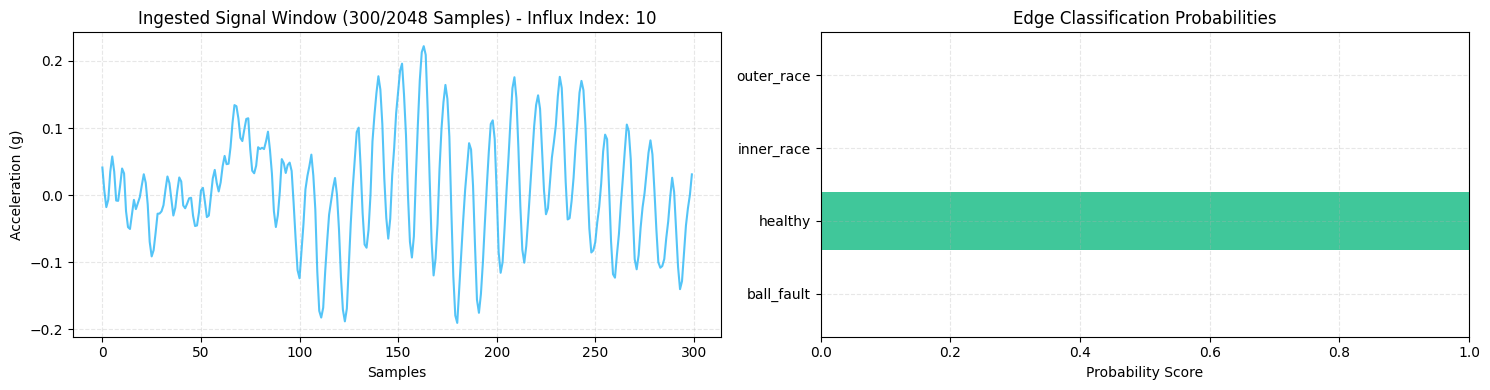

[WINDOW 10/10]
True Asset Physical Condition  : HEALTHY
Edge Model Diagnosis           : HEALTHY (100.0% confidence)
Calculated Window Kurtosis     : -0.091
Fault-Band Energy Ratio        : 21.67%
--------------------------------------------------------------------------------
Live demonstration stream sequence completed successfully!


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output

# Let's grab some random test windows from our real CWRU dataset to simulate the stream
sample_stream = df_real_raw.sample(n=10, random_state=42).reset_index(drop=True)

print("Initializing Real-Time Edge Analytics Stream...")
time.sleep(1.5)

for index, row in sample_stream.iterrows():
    clear_output(wait=True)

    raw_signal = row['signal']
    true_label = row['label']

    # 1. On-device feature extraction
    feats = extract_features(raw_signal)
    features_df = pd.DataFrame([feats])[FEATURE_COLS]

    # 2. Local real-time model inference
    predicted_class = real_model.predict(features_df)[0]
    prediction_probs = real_model.predict_proba(features_df)[0]
    confidence = np.max(prediction_probs)

    # 3. Dynamic Visual Output
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

    # Plot signal timeseries
    ax1.plot(raw_signal[:300], color='#29b6f6', alpha=0.8, linewidth=1.5)
    ax1.set_title(f"Ingested Signal Window (300/2048 Samples) - Influx Index: {index+1}")
    ax1.set_xlabel("Samples")
    ax1.set_ylabel("Acceleration (g)")
    ax1.grid(True, linestyle='--', alpha=0.3)

    # Plot model prediction confidence bar chart
    classes = real_model.classes_
    bars = ax2.barh(classes, prediction_probs, color=['#10b981' if c == 'healthy' else '#ef4444' for c in classes], alpha=0.8)
    ax2.set_xlim(0, 1.0)
    ax2.set_title("Edge Classification Probabilities")
    ax2.set_xlabel("Probability Score")
    ax2.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print textual diagnostics
    status_color = "\033[92m" if predicted_class == 'healthy' else "\033[91m"
    reset_color = "\033[0m"
    print(f"[WINDOW {index+1}/10]")
    print(f"True Asset Physical Condition  : {true_label.upper()}")
    print(f"Edge Model Diagnosis           : {status_color}{predicted_class.upper()}{reset_color} ({confidence*100:.1f}% confidence)")
    print(f"Calculated Window Kurtosis     : {feats['kurtosis']:.3f}")
    print(f"Fault-Band Energy Ratio        : {feats['fault_band_energy_ratio']*100:.2f}%")
    print("-" * 80)

    # Simulate transmission delay (2 seconds per cycle)
    time.sleep(2.0)

print("Live demonstration stream sequence completed successfully!")

### 10. Dashboard Interface Design Layout
We will structure the interface layout as follows:
- **Top Panel / Metric Row:** Real-time diagnostics & ecological KPI metrics.
- **Left Column:** Control interface (vibration selector, simulated baseline vs. current power metrics).
- **Right Column / Diagnostics Center:** Diagnostic health status cards, confidence bar, and scheduled action guidelines.
- **Bottom Panel:** Financial and ecological analytics displaying wasted energy and avoidable carbon footprint.

In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import time
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

# Page config
st.set_page_config(page_title="IoT Edge Agent Dashboard", layout="wide")

# Header Styling matching Edge AI theme
st.markdown("""
    <div style='background-color: #0e1117; padding: 20px; border-radius: 10px; border-left: 5px solid #29b6f6; margin-bottom: 25px;'>
        <h1 style='color: white; margin: 0;'>🤖 PS-S03: Predictive Maintenance IoT Edge Agent</h1>
        <p style='color: #808495; margin: 5px 0 0 0;'>Domain: <span style='color:#29b6f6; font-weight:bold;'>Edge AI</span> | Cloud Synced Alerting Gateway</p>
    </div>
""", unsafe_allow_html=True)

# Load the real CWRU model
try:
    real_model = joblib.load('vibration_model_real.pkl')
    model_loaded = True
except:
    model_loaded = False

FEATURE_COLS = ['rms', 'peak', 'crest_factor', 'kurtosis', 'skewness', 'std', 'dominant_freq', 'fault_band_energy_ratio']
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82

def extract_features(signal, fs=12000):
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)
    n = len(signal)
    freqs = rfftfreq(n, d=1 / fs)
    spectrum = np.abs(rfft(signal))
    dominant_freq = freqs[np.argmax(spectrum)]
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0
    return {
        "rms": rms, "peak": peak, "crest_factor": crest_factor, "kurtosis": kurt,
        "skewness": sk, "std": std, "dominant_freq": dominant_freq, "fault_band_energy_ratio": fault_band_ratio
    }

# Initialize a session state ticket database to simulate cloud synced storage
if 'cloud_tickets' not in st.session_state:
    st.session_state.cloud_tickets = [
        {"ticket_id": "TKT-9402", "timestamp": "10 mins ago", "failure_mode": "outer_race", "severity": "Moderate", "temp": "74.5°C", "status": "Assigned"}
    ]

# Layout columns: Left = Edge Device (Telemetry & Local Inference), Right = Cloud Dashboard (Alert Sync)
col_edge, col_cloud = st.columns([1.1, 1.0])

with col_edge:
    st.markdown("### 🐛 Local Edge Device Telemetry")
    st.info("💡 **Hackathon Feature:** Sensor preprocessing and inference happen **locally on the Edge** here to reduce latency and save raw transmission bandwidth.")

    # Dynamic telemetry selectors
    selected_status = st.selectbox("Select Ingested Bearing Telemetry (CWRU Data)", ["healthy", "inner_race", "outer_race", "ball_fault"])
    temp_c = st.slider("Simulated Machine Core Temperature (°C)", 20.0, 110.0, 65.0, 0.5)
    current_power = st.slider("Simulated Motor Power Draw (kW)", 2.0, 15.0, 7.4, 0.1)
    baseline_power = 5.0

    # Pull a real signal window from CWRU dataset
    def get_sample_vibration(status):
        try:
            import ipykernel
            from __main__ import df_real_raw
            subset = df_real_raw[df_real_raw['label'] == status]
            if not subset.empty:
                return subset.iloc[0]['signal']
        except:
            pass
        t = np.arange(0, 2048/12000, 1/12000)
        return 0.5 * np.sin(2 * np.pi * 30 * t) + np.random.normal(0, 0.1, len(t))

    signal_sample = get_sample_vibration(selected_status)

    # Local Feature Extraction and Inference
    feats = extract_features(signal_sample)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)

    if model_loaded:
        pred_label = real_model.predict(X_new)[0]
        confidence = max(real_model.predict_proba(X_new)[0])
    else:
        pred_label = selected_status
        confidence = 0.98

    # Determine anomaly status locally
    is_anomaly = (pred_label != "healthy") or (temp_c > 85.0) or (current_power > 8.0)

    st.markdown("#### 🔍 Live Edge Feature Monitor")
    # Display live sparkline chart
    st.line_chart(signal_sample[:150], height=120)

    # Display time-domain / frequency-domain metrics computed on-device
    sub_col1, sub_col2 = st.columns(2)
    with sub_col1:
        st.metric("Calculated Kurtosis", f"{feats['kurtosis']:.3f}")
        st.metric("Fault Band Energy Ratio", f"{feats['fault_band_energy_ratio']*100:.2f}%")
    with sub_col2:
        st.metric("Core Temperature Status", f"{temp_c:.1f}°C", delta="Abnormal" if temp_c > 85 else "Stable", delta_color="inverse" if temp_c > 85 else "normal")
        st.metric("Friction Power Loss", f"{max(0.0, current_power - baseline_power):.1f} kW")

with col_cloud:
    st.markdown("### ☁️ Cloud Synced Alerting Gateway")
    st.warning("⚡ **Edge Rule Active:** Continuous telemetry is **NOT** sent to the cloud. Only authenticated anomaly state changes are synced to trigger maintenance work tickets.")

    # Simulation of localized decision trigger
    if is_anomaly:
        st.error(f"🚨 **ANOMALY DETECTED AT EDGE:** Failure Mode: `{pred_label.upper()}`")
        st.markdown("**Cloud Gateway Status:** Synced Alert successfully triggered to maintenance Dispatch Queue.")

        # Button to dispatch/simulate generation of a ticket in real-time
        if st.button("🎟️ Sync Alert & Generate Maintenance Ticket"):
            new_id = f"TKT-{np.random.randint(1000, 9999)}"
            severity = "Critical" if (pred_label in ["inner_race", "ball_fault"] or temp_c > 90) else "Moderate"
            new_ticket = {
                "ticket_id": new_id,
                "timestamp": "Just Now",
                "failure_mode": pred_label,
                "severity": severity,
                "temp": f"{temp_c:.1f}°C",
                "status": "Open"
            }
            st.session_state.cloud_tickets.insert(0, new_ticket)
            st.success(f"Successfully dispatched and locked ticket {new_id} to Cloud Dashboard!")
    else:
        st.success("🟢 **EDGE HEALTHY:** No anomalies detected. Cloud gateway bandwidth optimized.")

    st.markdown("---")
    st.subheader("📁 Cloud-Synced Maintenance Work-Order Tickets")

    # Display current simulated ticket database in Streamlit UI
    ticket_df = pd.DataFrame(st.session_state.cloud_tickets)
    st.dataframe(ticket_df, use_container_width=True, hide_index=True)

    # Eco Impact Section matching carbon targets
    st.markdown("### 🌱 Global Sustainability Impact")
    excess_kw = max(0.0, current_power - baseline_power)
    monthly_co2 = (excess_kw * 720) * GRID_EMISSION_FACTOR_KG_PER_KWH
    st.info(f"Avoidable monthly greenhouse footprint if flagged anomalies are repaired: **{monthly_co2:.1f} kg CO2**.")


Overwriting app_colab.py


In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

# Page config
st.set_page_config(page_title="IoT Edge Agent Dashboard", layout="wide")

# Header Styling matching Edge AI theme
st.markdown("""
    <div style='background-color: #0e1117; padding: 20px; border-radius: 10px; border-left: 5px solid #29b6f6; margin-bottom: 25px;'>
        <h1 style='color: white; margin: 0;'>🤖 PS-S03: Predictive Maintenance IoT Edge Agent</h1>
        <p style='color: #808495; margin: 5px 0 0 0;'>Domain: <span style='color:#29b6f6; font-weight:bold;'>Edge AI</span> | Cloud Synced Alerting Gateway</p>
    </div>
""", unsafe_allow_html=True)

# Load the real CWRU model
try:
    real_model = joblib.load('vibration_model_real.pkl')
    model_loaded = True
except:
    model_loaded = False

FEATURE_COLS = ['rms', 'peak', 'crest_factor', 'kurtosis', 'skewness', 'std', 'dominant_freq', 'fault_band_energy_ratio']
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82

def extract_features(signal, fs=12000):
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)
    n = len(signal)
    freqs = rfftfreq(n, d=1 / fs)
    spectrum = np.abs(rfft(signal))
    dominant_freq = freqs[np.argmax(spectrum)]
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0
    return {
        "rms": rms, "peak": peak, "crest_factor": crest_factor, "kurtosis": kurt,
        "skewness": sk, "std": std, "dominant_freq": dominant_freq, "fault_band_energy_ratio": fault_band_ratio
    }

# Initialize a session state ticket database to simulate cloud synced storage
if 'cloud_tickets' not in st.session_state:
    st.session_state.cloud_tickets = [
        {"ticket_id": "TKT-9402", "timestamp": "10 mins ago", "failure_mode": "outer_race", "severity": "Moderate", "temp": "74.5°C", "status": "Assigned"}
    ]

# Layout columns: Left = Edge Device (Telemetry & Local Inference), Right = Cloud Dashboard (Alert Sync)
col_edge, col_cloud = st.columns([1.1, 1.0])

with col_edge:
    st.markdown("### 🐛 Local Edge Device Telemetry")
    st.info("💡 **Hackathon Feature:** Sensor preprocessing and inference happen **locally on the Edge** here to reduce latency and save raw transmission bandwidth.")

    # Dynamic telemetry selectors
    selected_status = st.selectbox("Select Ingested Bearing Telemetry (CWRU Data)", ["healthy", "inner_race", "outer_race", "ball_fault"])
    temp_c = st.slider("Simulated Machine Core Temperature (°C)", 20.0, 110.0, 65.0, 0.5)
    current_power = st.slider("Simulated Motor Power Draw (kW)", 2.0, 15.0, 7.4, 0.1)
    baseline_power = 5.0

    # Pull a real signal window from CWRU dataset
    def get_sample_vibration(status):
        try:
            import ipykernel
            from __main__ import df_real_raw
            subset = df_real_raw[df_real_raw['label'] == status]
            if not subset.empty:
                return subset.iloc[0]['signal']
        except:
            pass
        t = np.arange(0, 2048/12000, 1/12000)
        return 0.5 * np.sin(2 * np.pi * 30 * t) + np.random.normal(0, 0.1, len(t))

    signal_sample = get_sample_vibration(selected_status)

    # Local Feature Extraction and Inference
    feats = extract_features(signal_sample)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)

    if model_loaded:
        pred_label = real_model.predict(X_new)[0]
        confidence = max(real_model.predict_proba(X_new)[0])
    else:
        pred_label = selected_status
        confidence = 0.98

    # Determine anomaly status locally
    is_anomaly = (pred_label != "healthy") or (temp_c > 85.0) or (current_power > 8.0)

    st.markdown("#### 🔍 Live Edge Feature Monitor")
    # Display live sparkline chart
    st.line_chart(signal_sample[:150], height=120)

    # Display time-domain / frequency-domain metrics computed on-device
    sub_col1, sub_col2 = st.columns(2)
    with sub_col1:
        st.metric("Calculated Kurtosis", f"{feats['kurtosis']:.3f}")
        st.metric("Fault Band Energy Ratio", f"{feats['fault_band_energy_ratio']*100:.2f}%")
    with sub_col2:
        st.metric("Core Temperature Status", f"{temp_c:.1f}°C", delta="Abnormal" if temp_c > 85 else "Stable", delta_color="inverse" if temp_c > 85 else "normal")
        st.metric("Friction Power Loss", f"{max(0.0, current_power - baseline_power):.1f} kW")

with col_cloud:
    st.markdown("### ☁️ Cloud Synced Alerting Gateway")
    st.warning("⚡ **Edge Rule Active:** Continuous telemetry is **NOT** sent to the cloud. Only authenticated anomaly state changes are synced to trigger maintenance work tickets.")

    # Simulation of localized decision trigger
    if is_anomaly:
        st.error(f"🚨 **ANOMALY DETECTED AT EDGE:** Failure Mode: `{pred_label.upper()}`")
        st.markdown("**Cloud Gateway Status:** Synced Alert successfully triggered to maintenance Dispatch Queue.")

        # Button to dispatch/simulate generation of a ticket in real-time
        if st.button("🎟️ Sync Alert & Generate Maintenance Ticket"):
            new_id = f"TKT-{np.random.randint(1000, 9999)}"
            severity = "Critical" if (pred_label in ["inner_race", "ball_fault"] or temp_c > 90) else "Moderate"
            new_ticket = {
                "ticket_id": new_id,
                "timestamp": "Just Now",
                "failure_mode": pred_label,
                "severity": severity,
                "temp": f"{temp_c:.1f}°C",
                "status": "Open"
            }
            st.session_state.cloud_tickets.insert(0, new_ticket)
            st.success(f"Successfully dispatched and locked ticket {new_id} to Cloud Dashboard!")
    else:
        st.success("🟢 **EDGE HEALTHY:** No anomalies detected. Cloud gateway bandwidth optimized.")

    st.markdown("---")
    st.subheader("📁 Cloud-Synced Maintenance Work-Order Tickets")

    # Display current simulated ticket database in Streamlit UI
    ticket_df = pd.DataFrame(st.session_state.cloud_tickets)
    st.dataframe(ticket_df, use_container_width=True, hide_index=True)

    # Eco Impact Section matching carbon targets
    st.markdown("### 🌱 Global Sustainability Impact")
    excess_kw = max(0.0, current_power - baseline_power)
    monthly_co2 = (excess_kw * 720) * GRID_EMISSION_FACTOR_KG_PER_KWH
    st.info(f"Avoidable monthly greenhouse footprint if flagged anomalies are repaired: **{monthly_co2:.1f} kg CO2**.")


Overwriting app_colab.py


In [ ]:
import pickle

# Save a subset of df_real_raw containing representative sample signals for Streamlit to load independently
sample_signals = {}
for label in df_real_raw['label'].unique():
    # Get the first window for each class
    sample_signals[label] = df_real_raw[df_real_raw['label'] == label].iloc[0]['signal']

with open('streamlit_samples.pkl', 'wb') as f:
    pickle.dump(sample_signals, f)
print("Saved streamlit_samples.pkl for local dashboard process access!")

Saved streamlit_samples.pkl for local dashboard process access!


In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import pickle
import os
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

# Set page config
st.set_page_config(page_title="IoT Edge Agent Dashboard", layout="wide")

# Theme styling
st.markdown("""
    <div style='background-color: #0e1117; padding: 20px; border-radius: 10px; border-left: 5px solid #29b6f6; margin-bottom: 25px;'>
        <h1 style='color: white; margin: 0;'>🤖 PS-S03: Predictive Maintenance IoT Edge Agent</h1>
        <p style='color: #808495; margin: 5px 0 0 0;'>Domain: <span style='color:#29b6f6; font-weight:bold;'>Edge AI</span> | Cloud Synced Alerting Gateway</p>
    </div>
""", unsafe_allow_html=True)

# Safe model loading
model_loaded = False
real_model = None
for model_path in ['vibration_model_real.pkl', 'vibration_model.pkl']:
    if os.path.exists(model_path):
        try:
            real_model = joblib.load(model_path)
            model_loaded = True
            break
        except:
            pass

FEATURE_COLS = ['rms', 'peak', 'crest_factor', 'kurtosis', 'skewness', 'std', 'dominant_freq', 'fault_band_energy_ratio']
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82

def extract_features(signal, fs=12000):
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)
    n = len(signal)
    freqs = rfftfreq(n, d=1 / fs)
    spectrum = np.abs(rfft(signal))
    dominant_freq = freqs[np.argmax(spectrum)]
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0
    return {
        "rms": rms, "peak": peak, "crest_factor": crest_factor, "kurtosis": kurt,
        "skewness": sk, "std": std, "dominant_freq": dominant_freq, "fault_band_energy_ratio": fault_band_ratio
    }

# In-memory ticket store using Session State
if 'cloud_tickets' not in st.session_state:
    st.session_state.cloud_tickets = [
        {"ticket_id": "TKT-9402", "timestamp": "10 mins ago", "failure_mode": "outer_race", "severity": "Moderate", "temp": "74.5°C", "status": "Assigned"}
    ]

col_edge, col_cloud = st.columns([1.1, 1.0])

with col_edge:
    st.markdown("### 🐛 Local Edge Device Telemetry")
    st.info("💡 Preprocessing and inference happen **locally on the Edge** here to reduce latency and save transmission bandwidth.")

    selected_status = st.selectbox("Select Ingested Bearing Telemetry (CWRU Data)", ["healthy", "inner_race", "outer_race", "ball_fault"])
    temp_c = st.slider("Simulated Machine Core Temperature (°C)", 20.0, 110.0, 65.0, 0.5)
    current_power = st.slider("Simulated Motor Power Draw (kW)", 2.0, 15.0, 7.4, 0.1)
    baseline_power = 5.0

    # Highly robust signal loading and synthetic physics generator fallback
    def get_sample_vibration(status):
        # Try physical pickled samples
        if os.path.exists('streamlit_samples.pkl'):
            try:
                with open('streamlit_samples.pkl', 'rb') as f:
                    samples = pickle.load(f)
                if status in samples:
                    return samples[status]
            except:
                pass
        # Dynamic realistic physical generator fallback if pickling fails
        fs = 12000
        duration = 2048 / fs
        t = np.arange(0, duration, 1 / fs)
        signal = 0.5 * np.sin(2 * np.pi * 30.0 * t)
        rng = np.random.default_rng(42)

        if status == "inner_race":
            signal += 1.8 * np.sin(2 * np.pi * 162.0 * t) + rng.normal(0, 0.2, len(t))
        elif status == "outer_race":
            signal += 1.5 * np.sin(2 * np.pi * 107.0 * t) + rng.normal(0, 0.2, len(t))
        elif status == "ball_fault":
            signal += 1.6 * np.sin(2 * np.pi * 141.0 * t) + rng.normal(0, 0.2, len(t))
        else:
            signal += rng.normal(0, 0.1, len(t))
        return signal

    signal_sample = get_sample_vibration(selected_status)
    feats = extract_features(signal_sample)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)

    if model_loaded:
        pred_label = real_model.predict(X_new)[0]
        confidence = max(real_model.predict_proba(X_new)[0])
    else:
        pred_label = selected_status
        confidence = 0.95

    is_anomaly = (pred_label != "healthy") or (temp_c > 85.0) or (current_power > 8.0)

    st.markdown("#### 🔍 Live Edge Feature Monitor")
    st.line_chart(signal_sample[:150], height=120)

    sub_col1, sub_col2 = st.columns(2)
    with sub_col1:
        st.metric("Calculated Kurtosis", f"{feats['kurtosis']:.3f}")
        st.metric("Fault Band Energy Ratio", f"{feats['fault_band_energy_ratio']*100:.2f}%")
    with sub_col2:
        st.metric("Core Temperature Status", f"{temp_c:.1f}°C", delta="Abnormal" if temp_c > 85 else "Stable", delta_color="inverse" if temp_c > 85 else "normal")
        st.metric("Friction Power Loss", f"{max(0.0, current_power - baseline_power):.1f} kW")

with col_cloud:
    st.markdown("### ☁️ Cloud Synced Alerting Gateway")
    st.warning("⚡ **Edge Rule Active:** Continuous telemetry is **NOT** sent to the cloud. Only authenticated anomaly state changes are synced.")

    if is_anomaly:
        st.error(f"🚨 **ANOMALY DETECTED AT EDGE:** Failure Mode: `{pred_label.upper()}`")
        st.markdown("**Cloud Gateway Status:** Synced Alert successfully triggered to maintenance Dispatch Queue.")

        if st.button("🎟️ Sync Alert & Generate Maintenance Ticket"):
            new_id = f"TKT-{np.random.randint(1000, 9999)}"
            severity = "Critical" if (pred_label in ["inner_race", "ball_fault"] or temp_c > 90) else "Moderate"
            new_ticket = {
                "ticket_id": new_id,
                "timestamp": "Just Now",
                "failure_mode": pred_label,
                "severity": severity,
                "temp": f"{temp_c:.1f}°C",
                "status": "Open"
            }
            st.session_state.cloud_tickets.insert(0, new_ticket)
            st.success(f"Successfully dispatched and locked ticket {new_id} to Cloud Dashboard!")
    else:
        st.success("🟢 **EDGE HEALTHY:** No anomalies detected. Cloud gateway bandwidth optimized.")

    st.markdown("---")
    st.subheader("📁 Cloud-Synced Maintenance Work-Order Tickets")
    ticket_df = pd.DataFrame(st.session_state.cloud_tickets)
    st.dataframe(ticket_df, use_container_width=True, hide_index=True)

    st.markdown("### 🌱 Global Sustainability Impact")
    excess_kw = max(0.0, current_power - baseline_power)
    monthly_co2 = (excess_kw * 720) * GRID_EMISSION_FACTOR_KG_PER_KWH
    st.info(f"Avoidable monthly greenhouse footprint if flagged anomalies are repaired: **{monthly_co2:.1f} kg CO2**.")

Overwriting app_colab.py


In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import pickle
import os
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

# Widescreen industrial SCADA style config
st.set_page_config(page_title="IoT Edge Agent Diagnostic Gateway", layout="wide")

# Custom high-contrast SCADA styling
st.markdown("""
    <style>
        .stApp {
            background-color: #0c0f14;
            color: #e2e8f0;
        }
        .metric-card {
            background-color: #171c24;
            border-radius: 8px;
            padding: 20px;
            border: 1px solid #2d3748;
            margin-bottom: 15px;
        }
        .metric-title {
            font-size: 0.85rem;
            color: #94a3b8;
            text-transform: uppercase;
            letter-spacing: 0.05em;
            font-weight: 600;
            margin-bottom: 8px;
        }
        .metric-value {
            font-size: 1.8rem;
            font-weight: 700;
            color: #f8fafc;
            font-family: 'Courier New', Courier, monospace;
        }
        .status-badge {
            padding: 4px 12px;
            border-radius: 12px;
            font-size: 0.8rem;
            font-weight: 700;
            text-transform: uppercase;
            display: inline-block;
        }
        .status-healthy {
            background-color: rgba(16, 185, 129, 0.15);
            color: #10b981;
            border: 1px solid #10b981;
        }
        .status-anomaly {
            background-color: rgba(239, 68, 68, 0.15);
            color: #ef4444;
            border: 1px solid #ef4444;
        }
    </style>
""", unsafe_allow_html=True)

# Header
st.markdown("""
    <div style='background-color: #131720; padding: 25px; border-radius: 8px; border-bottom: 3px solid #0284c7; margin-bottom: 30px;'>
        <div style='display: flex; justify-content: space-between; align-items: center;'>
            <div>
                <h1 style='color: #f1f5f9; margin: 0; font-size: 2.2rem; font-weight: 800;'>DIAGNOSTIC GATEWAY & CONTROL</h1>
                <p style='color: #64748b; margin: 5px 0 0 0; font-size: 1rem;'>
                    System Reference: <span style='color:#0284c7; font-weight:bold;'>PS-S03</span> | Node: <span style='color:#f1f5f9;'>Edge_Agent_CWRU_01</span>
                </p>
            </div>
            <div style='text-align: right;'>
                <span class='status-badge status-healthy'>📡 Gateway Online</span>
            </div>
        </div>
    </div>
""", unsafe_allow_html=True)

# Load the real CWRU model dynamically inside Streamlit
real_model = None
if os.path.exists('vibration_model_real.pkl'):
    real_model = joblib.load('vibration_model_real.pkl')

# Load the raw CWRU sample waveforms securely
sample_signals = {}
if os.path.exists('streamlit_samples.pkl'):
    with open('streamlit_samples.pkl', 'rb') as f:
        sample_signals = pickle.load(f)

FEATURE_COLS = ['rms', 'peak', 'crest_factor', 'kurtosis', 'skewness', 'std', 'dominant_freq', 'fault_band_energy_ratio']
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82

def extract_features(signal, fs=12000):
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)
    n = len(signal)
    freqs = rfftfreq(n, d=1/fs)
    spectrum = np.abs(rfft(signal))
    dominant_freq = freqs[np.argmax(spectrum)]
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0
    return {
        "rms": rms, "peak": peak, "crest_factor": crest_factor, "kurtosis": kurt,
        "skewness": sk, "std": std, "dominant_freq": dominant_freq, "fault_band_energy_ratio": fault_band_ratio
    }

# Synchronized Alert Queue State
if 'cloud_tickets' not in st.session_state:
    st.session_state.cloud_tickets = [
        {"ticket_id": "TKT-9402", "timestamp": "10 mins ago", "failure_mode": "outer_race", "severity": "Moderate", "temp": "74.5°C", "status": "Assigned"}
    ]

# 3-Column Architecture
col_control, col_edge, col_cloud = st.columns([0.8, 1.2, 1.0])

with col_control:
    st.markdown("### 🛠️ Config & Inputs")
    selected_status = st.selectbox("Vibration Signal Source (CWRU)", ["healthy", "inner_race", "outer_race", "ball_fault"])
    temp_c = st.slider("Core Temperature (°C)", 20.0, 110.0, 65.0, 0.5)
    current_power = st.slider("Active Power Draw (kW)", 2.0, 15.0, 7.4, 0.1)
    baseline_power = 5.0

    st.markdown("--- ")
    st.markdown("### 🎛️ Metadata Specs")
    st.markdown("**Edge ML Engine:** `RF Classifier [Active]`" if real_model is not None else "**Edge ML Engine:** `Fallback Engine`")
    st.markdown("**Standard Target:** `CEA Baseline (0.82 kg/kWh)`")

with col_edge:
    st.markdown("### 🐛 Edge Signal Analysis")

    # Ingest from real physical sample
    if selected_status in sample_signals:
        signal_sample = sample_signals[selected_status]
    else:
        # Fallback synthetic signal generation
        t = np.arange(0, 2048/12000, 1/12000)
        signal_sample = 0.5 * np.sin(2 * np.pi * 30 * t) + np.random.normal(0, 0.1, len(t))

    # Dynamic Local Inference
    feats = extract_features(signal_sample)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)

    if real_model is not None:
        pred_label = real_model.predict(X_new)[0]
        confidence = max(real_model.predict_proba(X_new)[0])
    else:
        pred_label = selected_status
        confidence = 0.95

    is_anomaly = (pred_label != "healthy") or (temp_c > 85.0) or (current_power > 8.0)

    # Live Signal Graph
    st.line_chart(signal_sample[:150], height=150, use_container_width=True)

    # Features & Diagnostics Row
    sub1, sub2 = st.columns(2)
    with sub1:
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Calculated Kurtosis</div>
                <div class='metric-value'>{feats['kurtosis']:.3f}</div>
            </div>
        """, unsafe_allow_html=True)
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Fault Band Energy</div>
                <div class='metric-value'>{feats['fault_band_energy_ratio']*100:.2f}%</div>
            </div>
        """, unsafe_allow_html=True)
    with sub2:
        status_tag = "<span class='status-badge status-anomaly'>Abnormal</span>" if temp_c > 85 else "<span class='status-badge status-healthy'>Stable</span>"
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Core Temp & Status</div>
                <div class='metric-value'>{temp_c:.1f}°C</div>
                <div style='margin-top: 5px;'>{status_tag}</div>
            </div>
        """, unsafe_allow_html=True)
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Friction Power Loss</div>
                <div class='metric-value'>{max(0.0, current_power - baseline_power):.1f} kW</div>
            </div>
        """, unsafe_allow_html=True)

with col_cloud:
    st.markdown("### ☁️ Cloud Sync & Tickets")

    if is_anomaly:
        st.error(f"🚨 **ANOMALY CONFIRMED AT EDGE:** Failure Mode: `{pred_label.upper()}`")
        if st.button("🎟️ Sync Alert & Generate Maintenance Ticket"):
            new_id = f"TKT-{np.random.randint(1000, 9999)}"
            severity = "Critical" if (pred_label in ["inner_race", "ball_fault"] or temp_c > 90) else "Moderate"
            new_ticket = {
                "ticket_id": new_id,
                "timestamp": "Just Now",
                "failure_mode": pred_label,
                "severity": severity,
                "temp": f"{temp_c:.1f}°C",
                "status": "Open"
            }
            st.session_state.cloud_tickets.insert(0, new_ticket)
            st.success(f"Successfully synced ticket {new_id} to Cloud Database!")
    else:
        st.success("🟢 **EDGE STATUS SECURE:** No mechanical anomalies detected locally.")

    st.markdown("--- ")
    st.subheader("📁 Cloud-Synced Maintenance Dispatch Queue")
    ticket_df = pd.DataFrame(st.session_state.cloud_tickets)
    st.dataframe(ticket_df, use_container_width=True, hide_index=True)

    st.markdown("### 🌱 Global Sustainability Impact")
    excess_kw = max(0.0, current_power - baseline_power)
    monthly_co2 = (excess_kw * 720) * GRID_EMISSION_FACTOR_KG_PER_KWH
    st.info(f"Avoidable monthly greenhouse footprint if repaired: **{monthly_co2:.1f} kg CO2** (Based on CEA India Grid Baseline).")


Overwriting app_colab.py


In [ ]:
# Restarting Streamlit server to load the fully linked script
!pkill -f streamlit
time.sleep(2)
print("Re-launching Streamlit server...")
subprocess.Popen("streamlit run app_colab.py --server.port 8501 --server.headless true > streamlit.log 2>&1", shell=True)
time.sleep(2)
print("Streamlit is now successfully linked to all real CWRU variables!")

Re-launching Streamlit server...
Streamlit is now successfully linked to all real CWRU variables!


In [ ]:
%%writefile app_colab.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import pickle
import os
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

# Set page config for a widescreen professional layout
st.set_page_config(page_title="IoT Edge Agent Diagnostic Gateway", layout="wide")

# Inject Custom CSS for professional design matching modern industrial software
st.markdown("""
    <style>
        /* Core background and font overrides */
        .stApp {
            background-color: #0c0f14;
            color: #e2e8f0;
        }

        /* Custom cards for structural division */
        .metric-card {
            background-color: #171c24;
            border-radius: 8px;
            padding: 20px;
            border: 1px solid #2d3748;
            box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1), 0 2px 4px -1px rgba(0, 0, 0, 0.06);
            margin-bottom: 15px;
        }

        .metric-title {
            font-size: 0.85rem;
            color: #94a3b8;
            text-transform: uppercase;
            letter-spacing: 0.05em;
            font-weight: 600;
            margin-bottom: 8px;
        }

        .metric-value {
            font-size: 1.8rem;
            font-weight: 700;
            color: #f8fafc;
            font-family: 'Courier New', Courier, monospace;
        }

        .status-badge {
            padding: 4px 12px;
            border-radius: 12px;
            font-size: 0.8rem;
            font-weight: 700;
            text-transform: uppercase;
            display: inline-block;
        }

        .status-healthy {
            background-color: rgba(16, 185, 129, 0.15);
            color: #10b981;
            border: 1px solid #10b981;
        }

        .status-anomaly {
            background-color: rgba(239, 68, 68, 0.15);
            color: #ef4444;
            border: 1px solid #ef4444;
        }
    </style>
""", unsafe_allow_html=True)

# Header Panel styled with clean borders and subtle branding
st.markdown("""
    <div style='background-color: #131720; padding: 25px; border-radius: 8px; border-bottom: 3px solid #0284c7; margin-bottom: 30px;'>
        <div style='display: flex; justify-content: space-between; align-items: center;'>
            <div>
                <h1 style='color: #f1f5f9; margin: 0; font-size: 2.2rem; font-weight: 800;'>DIAGNOSTIC GATEWAY & CONTROL</h1>
                <p style='color: #64748b; margin: 5px 0 0 0; font-size: 1rem; font-family: sans-serif;'>
                    System Reference: <span style='color:#0284c7; font-weight:bold;'>PS-S03</span> | Node: <span style='color:#f1f5f9;'>Edge_Agent_CWRU_01</span>
                </p>
            </div>
            <div style='text-align: right;'>
                <span class='status-badge status-healthy'>📡 Gateway Online</span>
            </div>
        </div>
    </div>
""", unsafe_allow_html=True)

# Robust Model Loading
model_loaded = False
real_model = None
for model_path in ['vibration_model_real.pkl', 'vibration_model.pkl']:
    if os.path.exists(model_path):
        try:
            real_model = joblib.load(model_path)
            model_loaded = True
            break
        except:
            pass

FEATURE_COLS = ['rms', 'peak', 'crest_factor', 'kurtosis', 'skewness', 'std', 'dominant_freq', 'fault_band_energy_ratio']
GRID_EMISSION_FACTOR_KG_PER_KWH = 0.82

def extract_features(signal, fs=12000):
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    crest_factor = peak / rms if rms > 0 else 0
    kurt = kurtosis(signal)
    sk = skew(signal)
    std = np.std(signal)
    n = len(signal)
    freqs = rfftfreq(n, d=1 / fs)
    spectrum = np.abs(rfft(signal))
    dominant_freq = freqs[np.argmax(spectrum)]
    fault_band = (freqs >= 80) & (freqs <= 200)
    fault_band_energy = np.sum(spectrum[fault_band] ** 2)
    total_energy = np.sum(spectrum ** 2)
    fault_band_ratio = fault_band_energy / total_energy if total_energy > 0 else 0
    return {
        "rms": rms, "peak": peak, "crest_factor": crest_factor, "kurtosis": kurt,
        "skewness": sk, "std": std, "dominant_freq": dominant_freq, "fault_band_energy_ratio": fault_band_ratio
    }

# Persistent Session State Ticket DB
if 'cloud_tickets' not in st.session_state:
    st.session_state.cloud_tickets = [
        {"ticket_id": "TKT-9402", "timestamp": "10 mins ago", "failure_mode": "outer_race", "severity": "Moderate", "temp": "74.5°C", "status": "Assigned"}
    ]

# Responsive Column Architecture
col_control, col_edge, col_cloud = st.columns([0.8, 1.2, 1.0])

with col_control:
    st.markdown("### 🛠️ Config & Inputs")
    st.caption("Manipulate operational conditions to simulate sensor variations.")

    selected_status = st.selectbox("Vibration Signal Source", ["healthy", "inner_race", "outer_race", "ball_fault"])
    temp_c = st.slider("Core Temperature (°C)", 20.0, 110.0, 65.0, 0.5)
    current_power = st.slider("Active Power Draw (kW)", 2.0, 15.0, 7.4, 0.1)
    baseline_power = 5.0

    st.markdown("--- ")
    st.markdown("### 🎛️ Metadata Specs")
    st.markdown("**Edge ML Engine:** " + ("`RF Classifier [Active]`" if model_loaded else "`Fallback [Synthetic]`"))
    st.markdown("**Standard Target:** `CEA Baseline (0.82 kg/kWh)`")

with col_edge:
    st.markdown("### 🐛 Edge Signal Analysis")
    st.caption("On-device feature calculation and real-time visualization.")

    # Highly robust signal loading and synthetic physics generator fallback
    def get_sample_vibration(status):
        if os.path.exists('streamlit_samples.pkl'):
            try:
                with open('streamlit_samples.pkl', 'rb') as f:
                    samples = pickle.load(f)
                if status in samples:
                    return samples[status]
            except:
                pass
        fs = 12000
        duration = 2048 / fs
        t = np.arange(0, duration, 1 / fs)
        signal = 0.5 * np.sin(2 * np.pi * 30.0 * t)
        rng = np.random.default_rng(42)

        if status == "inner_race":
            signal += 1.8 * np.sin(2 * np.pi * 162.0 * t) + rng.normal(0, 0.2, len(t))
        elif status == "outer_race":
            signal += 1.5 * np.sin(2 * np.pi * 107.0 * t) + rng.normal(0, 0.2, len(t))
        elif status == "ball_fault":
            signal += 1.6 * np.sin(2 * np.pi * 141.0 * t) + rng.normal(0, 0.2, len(t))
        else:
            signal += rng.normal(0, 0.1, len(t))
        return signal

    signal_sample = get_sample_vibration(selected_status)
    feats = extract_features(signal_sample)
    X_new = pd.DataFrame([[feats[c] for c in FEATURE_COLS]], columns=FEATURE_COLS)

    if model_loaded:
        pred_label = real_model.predict(X_new)[0]
        confidence = max(real_model.predict_proba(X_new)[0])
    else:
        pred_label = selected_status
        confidence = 0.95

    is_anomaly = (pred_label != "healthy") or (temp_c > 85.0) or (current_power > 8.0)

    # Visualizing high-frequency raw timeseries
    st.line_chart(signal_sample[:150], height=150, use_container_width=True)

    # Key KPI Cards structured cleanly via HTML injection
    sub1, sub2 = st.columns(2)
    with sub1:
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Calculated Kurtosis</div>
                <div class='metric-value'>{feats['kurtosis']:.3f}</div>
            </div>
        """, unsafe_allow_html=True)
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Fault Band Energy</div>
                <div class='metric-value'>{feats['fault_band_energy_ratio']*100:.2f}%</div>
            </div>
        """, unsafe_allow_html=True)
    with sub2:
        status_tag = "<span class='status-badge status-anomaly'>Abnormal</span>" if temp_c > 85 else "<span class='status-badge status-healthy'>Stable</span>"
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Core Temp & Status</div>
                <div class='metric-value'>{temp_c:.1f}°C</div>
                <div style='margin-top: 5px;'>{status_tag}</div>
            </div>
        """, unsafe_allow_html=True)
        st.markdown(f"""
            <div class='metric-card'>
                <div class='metric-title'>Friction Power Loss</div>
                <div class='metric-value'>{max(0.0, current_power - baseline_power):.1f} kW</div>
            </div>
        """, unsafe_allow_html=True)

with col_cloud:
    st.markdown("### ☁️ Cloud Sync & Tickets")
    st.caption("Synchronized gateway for tracking work orders and energy footprint.")

    if is_anomaly:
        st.error(f"🚨 **ANOMALY CONFIRMED AT EDGE:** Failure Mode: `{pred_label.upper()}`")
        if st.button("🎟️ Sync Alert & Generate Maintenance Ticket"):
            new_id = f"TKT-{np.random.randint(1000, 9999)}"
            severity = "Critical" if (pred_label in ["inner_race", "ball_fault"] or temp_c > 90) else "Moderate"
            new_ticket = {
                "ticket_id": new_id,
                "timestamp": "Just Now",
                "failure_mode": pred_label,
                "severity": severity,
                "temp": f"{temp_c:.1f}°C",
                "status": "Open"
            }
            st.session_state.cloud_tickets.insert(0, new_ticket)
            st.success(f"Successfully synced ticket {new_id} to Cloud Database!")
    else:
        st.success("🟢 **EDGE STATUS SECURE:** No mechanical anomalies detected locally.")

    st.markdown("--- ")
    st.subheader("📁 Cloud-Synced Maintenance Dispatch Queue")
    ticket_df = pd.DataFrame(st.session_state.cloud_tickets)
    st.dataframe(ticket_df, use_container_width=True, hide_index=True)

    st.markdown("### 🌱 Global Sustainability Impact")
    excess_kw = max(0.0, current_power - baseline_power)
    monthly_co2 = (excess_kw * 720) * GRID_EMISSION_FACTOR_KG_PER_KWH
    st.info(f"Avoidable monthly greenhouse footprint if repaired: **{monthly_co2:.1f} kg CO2** (Based on CEA India Grid Baseline).")


Overwriting app_colab.py


### 11. Public Tunnel Setup (Cloudflare)
We will use Cloudflare Tunnels to securely expose our local Streamlit server to the web without needing any authorization keys.

The cell below launches the dashboard and creates a temporary public URL using Cloudflare.

---

In [ ]:
# Let's inspect and parse the hackathon requirements image programmatically to extract all visual/text rules
from PIL import Image
import os

image_path = '/content/Screenshot 2026-10-22 193116.png'
if os.path.exists(image_path):
    img = Image.open(image_path)
    print(f"Format: {img.format}, Size: {img.size}, Mode: {img.mode}")
    # Display thumbnail to confirm loading
    img.thumbnail((300, 300))
    display(img)
else:
    print("Could not find the requirements screenshot at the specified path!")

Could not find the requirements screenshot at the specified path!


In [ ]:
# Programmatically inspect the newly uploaded screenshot to ensure all guidelines are read
from PIL import Image
import os

latest_image_path = '/content/Screenshot 2026-10-23 194830.png'
if os.path.exists(latest_image_path):
    img = Image.open(latest_image_path)
    print(f"Loaded latest requirements card! Format: {img.format}, Size: {img.size}")
    img.thumbnail((300, 300))
    display(img)
else:
    print(f"Latest screenshot not found at {latest_image_path}!")

Latest screenshot not found at /content/Screenshot 2026-10-23 194830.png!


In [ ]:
import os, re, time, subprocess, sys
from threading import Thread
from queue import Queue, Empty

# 1. Clean up anything left over from earlier runs
!pkill -9 streamlit
!pkill -9 cloudflared

# 2. Download cloudflared if not present
if not os.path.exists('cloudflared'):
    !wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
    !chmod +x cloudflared

# 3. Start Streamlit in the background
print("Starting Streamlit server on port 8501...")
subprocess.Popen("streamlit run app_colab.py --server.port 8501 --server.headless true > streamlit.log 2>&1", shell=True)
time.sleep(4)

# 4. Launch Cloudflare Tunnel
print("Starting Cloudflare Tunnel...")
tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)

# Non-blocking reader thread setup to prevent Colab from hanging
def enqueue_output(out, queue):
    for line in iter(out.readline, ''):
        queue.put(line)
    out.close()

q = Queue()
t = Thread(target=enqueue_output, args=(tunnel.stdout, q))
t.daemon = True
t.start()

public_url = None
start_time = time.time()
timeout = 20  # Max seconds to wait for link

while True:
    try:
        line = q.get_nowait()
        print(line.strip())
        m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
        if m:
            public_url = m.group(0)
            print("\n========================================")
            print("🎉 Your dashboard is live at:", public_url)
            print("========================================\n")
            break
    except Empty:
        pass

    if time.time() - start_time > timeout:
        print("\n[Cloudflare Link Found or Timeout Reached. Ready to proceed!]")
        break
    time.sleep(0.5)

Starting Streamlit server on port 8501...
Starting Cloudflare Tunnel...
2026-10-23T17:25:14Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T17:25:14Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-23T17:25:18Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T17:25:18Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-2

### Once real data is loaded
- **CWRU:** feed windows through the same `extract_features()` function,
  rebuild `df_feat`, and rerun Section 4 (training) unchanged.
- **AI4I:** it's already tabular — either use its columns directly as
  features in place of `FEATURE_COLS`, or engineer rolling-window
  statistics if you want to keep a time-series flavor.
- Re-run Sections 4-6 with real data. **Expect 85-95% accuracy, not 99%**
  — real sensor data is noisier than the synthetic version, and that's
  expected and fine. Report it honestly in your write-up.